In [4]:
# ============================================================
# Survival preparation
# Median TFx per patient + Overall_Survival_days
# All available AURORA patients
# left_only  = has median TFx but missing OS
# right_only = has OS but missing median TFx
# both       = matched successfully
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

# Blood-draw-level TFx source
blood_draws_xlsx = (
    BASE_DIR /
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)

blood_draws_sheet = "Blood_draws"

# Clinical source for OS
clinical_xlsx = BASE_DIR / "Clinical_data/AUP_ClinicalData_20260609.xlsx"

clinical_sheet = "AUP_ClinicalData_20260609.NO.DA"

# Output directory
out_dir = BASE_DIR / "Survival"
out_dir.mkdir(parents=True, exist_ok=True)

out_clean_csv = out_dir / "AURORA_all_patients_median_TFx_OS_clean.csv"
out_extended_csv = out_dir / "AURORA_all_patients_median_TFx_OS_extended_QC.csv"
out_missing_os_csv = out_dir / "AURORA_patients_with_median_TFx_but_missing_OS.csv"
out_missing_tfx_csv = out_dir / "AURORA_patients_with_OS_but_missing_median_TFx.csv"

print("Blood draws workbook:")
print(blood_draws_xlsx)

print("\nClinical workbook:")
print(clinical_xlsx)

print("\nOutput directory:")
print(out_dir)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_patient_id(x):
    """
    Clean patient_id so numeric IDs match across files.

    Examples:
      2      -> "2"
      2.0    -> "2"
      "2.0"  -> "2"
      "588-21" -> "588-21"
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def find_first_col(df, candidates, label):
    for c in candidates:
        if c in df.columns:
            return c

    raise ValueError(
        f"Could not find {label}. Tried: {candidates}\n"
        f"Available columns:\n{df.columns.tolist()}"
    )


def safe_numeric(x):
    return pd.to_numeric(x, errors="coerce")


# ============================================================
# 3. Read Blood_draws sheet and calculate median TFx
# ============================================================

blood = pd.read_excel(
    blood_draws_xlsx,
    sheet_name=blood_draws_sheet,
    dtype=str
)

print("\n========== Blood_draws input ==========")
print("Rows:", blood.shape[0])
print("Columns:", blood.shape[1])
print(blood.columns.tolist())

blood_patient_col = find_first_col(
    blood,
    candidates=["patient_id", "Patient_ID", "patientID"],
    label="patient_id column in Blood_draws"
)

tfx_col = find_first_col(
    blood,
    candidates=[
        "Tumor_Fraction_percent_from_CNV_annotation",
        "Tumor_Fraction_percent",
        "TFx_percent",
        "Tumor_Fraction"
    ],
    label="TFx column in Blood_draws"
)

print("\nDetected Blood_draws columns:")
print("patient_id:", blood_patient_col)
print("TFx:", tfx_col)

blood["patient_id_clean"] = blood[blood_patient_col].apply(clean_patient_id)
blood["TFx_percent"] = safe_numeric(blood[tfx_col])

# If TFx accidentally appears as 0-1 fraction, convert to percent
if blood["TFx_percent"].dropna().shape[0] > 0:
    if blood["TFx_percent"].dropna().max() <= 1:
        print("\nTFx appears to be 0-1 fraction; converting to percent.")
        blood["TFx_percent"] = blood["TFx_percent"] * 100

# Keep all patients represented in Blood_draws, even if TFx is missing
all_tfx_patients = (
    blood.loc[blood["patient_id_clean"].notna(), ["patient_id_clean"]]
    .drop_duplicates()
    .copy()
)

median_tfx = (
    blood.loc[blood["patient_id_clean"].notna()]
    .groupby("patient_id_clean", dropna=False)
    .agg(
        median_TFx=("TFx_percent", "median"),
        n_blood_draw_rows=("TFx_percent", "size"),
        n_nonmissing_TFx=("TFx_percent", lambda x: x.notna().sum()),
        mean_TFx=("TFx_percent", "mean"),
        min_TFx=("TFx_percent", "min"),
        max_TFx=("TFx_percent", "max")
    )
    .reset_index()
)

# Make sure all patients remain included
median_tfx = all_tfx_patients.merge(
    median_tfx,
    on="patient_id_clean",
    how="left"
)

print("\n========== Median TFx summary ==========")
print("Patients in Blood_draws:", median_tfx.shape[0])
print("Patients with nonmissing median TFx:", median_tfx["median_TFx"].notna().sum())


# ============================================================
# 4. Read clinical sheet and extract Overall_Survival_days
# ============================================================

xls = pd.ExcelFile(clinical_xlsx)

print("\nAvailable clinical sheets:")
print(xls.sheet_names)

if clinical_sheet not in xls.sheet_names:
    possible = [s for s in xls.sheet_names if "NO.DA" in s or "ClinicalData" in s]
    print("\nCandidate sheets:", possible)
    raise ValueError(
        f"Requested sheet not found: {clinical_sheet}\n"
        f"Please update clinical_sheet using one of the available sheet names."
    )

clinical = pd.read_excel(
    clinical_xlsx,
    sheet_name=clinical_sheet,
    dtype=str
)

print("\n========== Clinical input ==========")
print("Rows:", clinical.shape[0])
print("Columns:", clinical.shape[1])
print(clinical.columns.tolist())

clinical_patient_col = find_first_col(
    clinical,
    candidates=["patient_id", "Patient_ID", "patientID"],
    label="patient_id column in clinical file"
)

category_col = find_first_col(
    clinical,
    candidates=["Category"],
    label="Category column"
)

os_time_col = find_first_col(
    clinical,
    candidates=[
        "Days_From_Primary_Diagnosis",
        "Overall_Survival_days",
        "OS_days"
    ],
    label="Overall survival days column"
)

clinical["patient_id_clean"] = clinical[clinical_patient_col].apply(clean_patient_id)

os_rows = clinical[
    clinical[category_col].astype(str).str.strip().eq("Overall_Survival_days")
].copy()

os_rows["Overall_Survival_days"] = safe_numeric(os_rows[os_time_col])

print("\n========== OS rows ==========")
print("OS rows:", os_rows.shape[0])
print("Unique patients with OS rows:", os_rows["patient_id_clean"].nunique())
print("Patients with numeric OS days:", os_rows.loc[os_rows["Overall_Survival_days"].notna(), "patient_id_clean"].nunique())

# Collapse OS to one row per patient
# If multiple OS rows exist for a patient, use max numeric OS_days and record n_OS_rows.
os_patient = (
    os_rows.loc[os_rows["patient_id_clean"].notna()]
    .groupby("patient_id_clean", dropna=False)
    .agg(
        Overall_Survival_days=("Overall_Survival_days", "max"),
        n_OS_rows=("Overall_Survival_days", "size"),
        n_numeric_OS_rows=("Overall_Survival_days", lambda x: x.notna().sum())
    )
    .reset_index()
)

print("\n========== Patient-level OS summary ==========")
print("Patients with OS row:", os_patient.shape[0])
print("Patients with numeric OS days:", os_patient["Overall_Survival_days"].notna().sum())


# ============================================================
# 5. Merge median TFx with OS by cleaned patient_id
# ============================================================

merged = median_tfx.merge(
    os_patient,
    on="patient_id_clean",
    how="outer",
    indicator=True
)

# ============================================================
# QC: print and save unmatched patient IDs
# ============================================================

# TFx-only patients: present in median TFx table, absent from OS table
tfx_only = merged.loc[
    merged["_merge"].eq("left_only"),
    [
        "patient_id_clean",
        "median_TFx",
        "n_blood_draw_rows",
        "n_nonmissing_TFx",
        "mean_TFx",
        "min_TFx",
        "max_TFx"
    ]
].copy()

# OS-only patients: present in OS table, absent from median TFx table
os_only = merged.loc[
    merged["_merge"].eq("right_only"),
    [
        "patient_id_clean",
        "Overall_Survival_days",
        "n_OS_rows",
        "n_numeric_OS_rows"
    ]
].copy()

# Sort for easier manual checking
tfx_only = tfx_only.sort_values("patient_id_clean")
os_only = os_only.sort_values("patient_id_clean")

print("\n========== Patients only in TFx table, missing OS ==========")
print("Number:", tfx_only.shape[0])
print(tfx_only.to_string(index=False))

print("\n========== Patients only in OS table, missing TFx ==========")
print("Number:", os_only.shape[0])
print(os_only.to_string(index=False))



# Rename patient_id for final output
merged = merged.rename(columns={"patient_id_clean": "patient_id"})

# Main clean file requested by user
clean_out = merged[
    [
        "patient_id",
        "median_TFx",
        "Overall_Survival_days"
    ]
].copy()

# Sort patient_id numerically where possible
def patient_sort_key(x):
    try:
        return (0, float(x))
    except Exception:
        return (1, str(x))

clean_out = clean_out.sort_values(
    by="patient_id",
    key=lambda s: s.map(patient_sort_key)
)

clean_out.to_csv(out_clean_csv, index=False)

# Extended QC file
extended_cols = [
    "patient_id",
    "median_TFx",
    "Overall_Survival_days",
    "n_blood_draw_rows",
    "n_nonmissing_TFx",
    "mean_TFx",
    "min_TFx",
    "max_TFx",
    "n_OS_rows",
    "n_numeric_OS_rows",
    "_merge"
]

extended_out = merged[[c for c in extended_cols if c in merged.columns]].copy()
extended_out = extended_out.sort_values(
    by="patient_id",
    key=lambda s: s.map(patient_sort_key)
)

extended_out.to_csv(out_extended_csv, index=False)

# Missingness QC files
missing_os = extended_out[
    extended_out["median_TFx"].notna()
    & extended_out["Overall_Survival_days"].isna()
].copy()

missing_tfx = extended_out[
    extended_out["Overall_Survival_days"].notna()
    & extended_out["median_TFx"].isna()
].copy()

missing_os.to_csv(out_missing_os_csv, index=False)
missing_tfx.to_csv(out_missing_tfx_csv, index=False)


# ============================================================
# 6. Final summary
# ============================================================

print("\n========== Final merge summary ==========")
print(merged["_merge"].value_counts(dropna=False).to_string())

print("\nFinal clean output rows:", clean_out.shape[0])
print("Patients with median_TFx:", clean_out["median_TFx"].notna().sum())
print("Patients with Overall_Survival_days:", clean_out["Overall_Survival_days"].notna().sum())
print(
    "Patients with both median_TFx and Overall_Survival_days:",
    clean_out["median_TFx"].notna().mul(clean_out["Overall_Survival_days"].notna()).sum()
)

print("\nMissing OS among patients with median TFx:", missing_os.shape[0])
print("Missing median TFx among patients with OS:", missing_tfx.shape[0])

print("\nSaved clean CSV:")
print(out_clean_csv)

print("\nSaved extended QC CSV:")
print(out_extended_csv)

print("\nSaved missingness files:")
print(out_missing_os_csv)
print(out_missing_tfx_csv)

print("\nPreview clean output:")
print(clean_out.head(20).to_string(index=False))

Blood draws workbook:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/All_cases_clinical_CNV_extraction_TSVs/All_cases_clinical_CNV_extraction.xlsx

Clinical workbook:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival

========== Blood_draws input ==========
Rows: 769
Columns: 38
['Patient_Identifier', 'patient_id', 'Site', 'mapping_status', 'Blood_Draw_Days_From_Primary_Diagnosis', 'Barcode', 'Clinical_ID', 'Clinical_ID_2', 'Active_treatment_at_draw', 'Treatment_context_at_draw', 'Most_recent_treatment_before_draw', 'Most_recent_treatment_start_day', 'Most_recent_treatment_end_day', 'Most_recent_treatment_response_recorded', 'Most_recent_treatment_progression_recorded', 'Most_recent_treatment_reason_ended_recorded', 'Most_recent_completed_treatment_before_draw', 'Most_recent_completed_treatment_end_day', 'Days_since_most_recent_completed_t

In [5]:
# ============================================================
# Add OS Event column to median TFx + OS clean file
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

survival_dir = BASE_DIR / "Survival"

clean_file = survival_dir / "AURORA_all_patients_median_TFx_OS_clean.csv"

clinical_xlsx = BASE_DIR / "Clinical_data/AUP_ClinicalData_20260609.xlsx"
clinical_sheet = "AUP_ClinicalData_20260609.NO.DA"

backup_file = survival_dir / "AURORA_all_patients_median_TFx_OS_clean_before_Event_backup.csv"
qc_file = survival_dir / "AURORA_all_patients_median_TFx_OS_Event_QC.csv"

print("Clean survival file:")
print(clean_file)

print("\nClinical Excel:")
print(clinical_xlsx)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_patient_id(x):
    """
    Clean patient_id for matching.

    Examples:
      2      -> "2"
      2.0    -> "2"
      "2.0"  -> "2"
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def code_event(x):
    """
    Code OS_event for KM analysis.

    Dead                 -> 1
    Alive with Disease   -> 0
    Lost to Follow Up    -> 0
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s == "dead":
        return 1

    if s in ["alive with disease", "lost to follow up", "lost to follow-up"]:
        return 0

    return pd.NA


def paste_unique(series, sep="; "):
    vals = []
    seen = set()

    for v in series:
        if pd.isna(v):
            continue

        s = str(v).strip()

        if s == "":
            continue

        if s not in seen:
            vals.append(s)
            seen.add(s)

    return sep.join(vals) if vals else pd.NA


# ============================================================
# 3. Read current clean survival file
# ============================================================

clean_df = pd.read_csv(clean_file, dtype={"patient_id": str})

print("\n========== Current clean file ==========")
print("Rows:", clean_df.shape[0])
print(clean_df.head().to_string(index=False))

clean_df["patient_id_clean"] = clean_df["patient_id"].apply(clean_patient_id)


# ============================================================
# 4. Read clinical sheet and extract OS_event rows
# ============================================================

clinical = pd.read_excel(
    clinical_xlsx,
    sheet_name=clinical_sheet,
    dtype=str
)

clinical["patient_id_clean"] = clinical["patient_id"].apply(clean_patient_id)

os_rows = clinical[
    clinical["Category"].astype(str).str.strip().eq("Overall_Survival_days")
].copy()

print("\n========== OS_event raw values from clinical OS rows ==========")
print(os_rows["OS_event"].fillna("Missing").value_counts(dropna=False).to_string())

os_rows["Event"] = os_rows["OS_event"].apply(code_event)

print("\n========== Coded Event values ==========")
print(os_rows["Event"].fillna("Missing").value_counts(dropna=False).to_string())


# ============================================================
# 5. Collapse to one Event value per patient
# ============================================================

event_rows = []

for pid, sub in os_rows.groupby("patient_id_clean", dropna=False):
    if pd.isna(pid):
        continue

    event_vals = sub["Event"].dropna().astype(int).tolist()

    # If any OS row says Dead, event = 1.
    # Otherwise, if alive/LTFU status exists, event = 0.
    if 1 in event_vals:
        event = 1
    elif 0 in event_vals:
        event = 0
    else:
        event = pd.NA

    event_rows.append({
        "patient_id_clean": pid,
        "Event": event,
        "OS_event_raw_all": paste_unique(sub["OS_event"]),
        "n_OS_event_rows": sub.shape[0]
    })

event_patient = pd.DataFrame(event_rows)

print("\n========== Patient-level Event summary ==========")
print("Patients with OS_event row:", event_patient.shape[0])
print(event_patient["Event"].fillna("Missing").value_counts(dropna=False).to_string())


# ============================================================
# 6. Merge Event into clean survival file
# ============================================================

merged = clean_df.merge(
    event_patient,
    on="patient_id_clean",
    how="left",
    indicator=True
)

print("\n========== Event merge QC ==========")
print(merged["_merge"].value_counts(dropna=False).to_string())

print("\nPatients with median_TFx + OS days + Event:")
print(
    merged[
        merged["median_TFx"].notna()
        & merged["Overall_Survival_days"].notna()
        & merged["Event"].notna()
    ].shape[0]
)

print("\nEvent distribution in final clean file:")
print(merged["Event"].fillna("Missing").value_counts(dropna=False).to_string())


# ============================================================
# 7. Save updated clean file
# ============================================================

final_clean = merged[
    [
        "patient_id",
        "median_TFx",
        "Overall_Survival_days",
        "Event"
    ]
].copy()

final_clean.to_csv(clean_file, index=False)

# Save QC file with raw labels
qc_out = merged[
    [
        "patient_id",
        "median_TFx",
        "Overall_Survival_days",
        "Event",
        "OS_event_raw_all",
        "n_OS_event_rows",
        "_merge"
    ]
].copy()

qc_out.to_csv(qc_file, index=False)

print("\nUpdated clean file saved:")
print(clean_file)

print("\nQC file saved:")
print(qc_file)

print("\nPreview updated clean file:")
print(final_clean.head(20).to_string(index=False))

Clean survival file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/AURORA_all_patients_median_TFx_OS_clean.csv

Clinical Excel:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx

========== Current clean file ==========
Rows: 273
patient_id  median_TFx  Overall_Survival_days
         1         NaN                 1007.0
         2       4.713                 1214.0
         4       8.742                 1324.0
         5       0.000                 5299.0
         6      50.170                  795.0

========== OS_event raw values from clinical OS rows ==========
Dead                  207
Alive with Disease     56
Lost to Follow Up       9

========== Coded Event values ==========
1    207
0     65

========== Patient-level Event summary ==========
Patients with OS_event row: 271
1    206
0     65

========== Event merge QC ==========
both          271
left_only       2
right_only      0

Patients with median_TFx + OS day

Input file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/AURORA_all_patients_median_TFx_OS_clean.csv

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/KM_median_TFx

========== Input summary ==========
Rows: 273
Columns: ['patient_id', 'median_TFx', 'Overall_Survival_days', 'Event']

========== Survival-ready cohort ==========
Patients: 260
Deaths/events: 197
Censored: 63

========== Median TFx grouping ==========
Median TFx cutpoint: 7.9905
Low median TFx     130
High median TFx    130

========== Log-rank test ==========
Chi-square: 6.7593807793506455
p-value: 0.009325611566616666


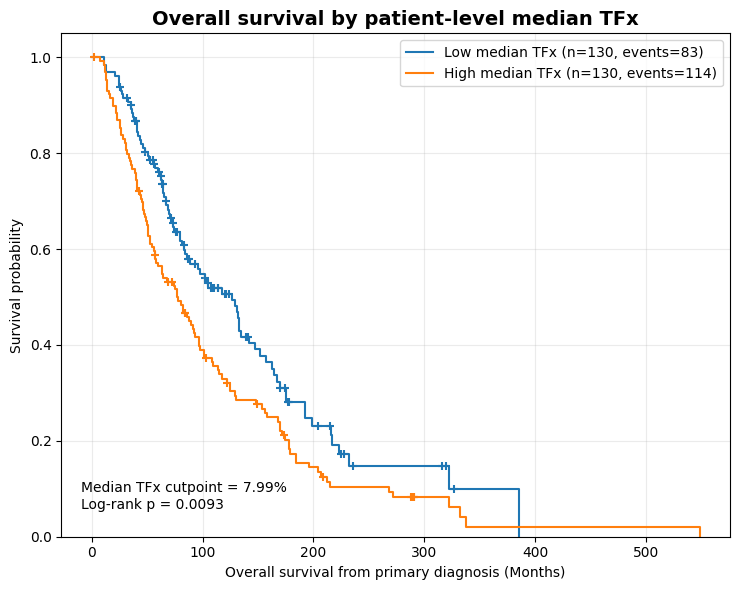


========== KM summary ==========
median_TFx_group  n_patients  n_events  n_censored  median_survival_months  median_TFx_cutpoint  logrank_chi_square  logrank_p_value
  Low median TFx         130        83          47              126.948665               7.9905            6.759381         0.009326
 High median TFx         130       114          16               77.305955               7.9905            6.759381         0.009326

Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/KM_median_TFx/KM_OS_by_high_low_median_TFx.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/KM_median_TFx/KM_OS_by_high_low_median_TFx.pdf
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/KM_median_TFx/KM_summary_OS_by_high_low_median_TFx.csv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/KM_median_TFx/KM_survival_ready_table.csv


In [6]:
# ============================================================
# Kaplan-Meier plot: Overall survival by patient-level median TFx
# Input file already contains:
# patient_id, median_TFx, Overall_Survival_days, Event
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

# ============================================================
# 1. Paths
# ============================================================

base_dir = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival")

input_file = base_dir / "AURORA_all_patients_median_TFx_OS_clean.csv"

out_dir = base_dir / "KM_median_TFx"
out_dir.mkdir(parents=True, exist_ok=True)

print("Input file:")
print(input_file)

print("\nOutput directory:")
print(out_dir)

# ============================================================
# 2. Read input
# ============================================================

df = pd.read_csv(input_file, dtype={"patient_id": str})

print("\n========== Input summary ==========")
print("Rows:", df.shape[0])
print("Columns:", df.columns.tolist())

required_cols = ["patient_id", "median_TFx", "Overall_Survival_days", "Event"]
missing_cols = [c for c in required_cols if c not in df.columns]

if len(missing_cols) > 0:
    raise ValueError(f"Missing required columns: {missing_cols}")

df["median_TFx"] = pd.to_numeric(df["median_TFx"], errors="coerce")
df["Overall_Survival_days"] = pd.to_numeric(df["Overall_Survival_days"], errors="coerce")
df["Event"] = pd.to_numeric(df["Event"], errors="coerce")

# Keep only survival-ready rows
surv = df[
    df["median_TFx"].notna()
    & df["Overall_Survival_days"].notna()
    & df["Event"].notna()
].copy()

surv["Event"] = surv["Event"].astype(int)

DAYS_PER_MONTH = 365.25 / 12
surv["Overall_Survival_months"] = surv["Overall_Survival_days"] / DAYS_PER_MONTH

print("\n========== Survival-ready cohort ==========")
print("Patients:", surv.shape[0])
print("Deaths/events:", int((surv["Event"] == 1).sum()))
print("Censored:", int((surv["Event"] == 0).sum()))

if surv.shape[0] == 0:
    raise RuntimeError("No survival-ready patients found.")

# ============================================================
# 3. Define high vs low median TFx groups
# ============================================================

median_cut = surv["median_TFx"].median()

surv["median_TFx_group"] = np.where(
    surv["median_TFx"] >= median_cut,
    "High median TFx",
    "Low median TFx"
)

print("\n========== Median TFx grouping ==========")
print(f"Median TFx cutpoint: {median_cut:.4f}")
print(surv["median_TFx_group"].value_counts().to_string())

surv_ready_file = out_dir / "KM_survival_ready_table.csv"
surv.to_csv(surv_ready_file, index=False)

# ============================================================
# 4. Helper functions for KM and log-rank
# ============================================================

def km_curve(durations, events):
    """
    Manual Kaplan-Meier estimator.
    Returns:
      x, y, event_table, median_survival
    """
    data = pd.DataFrame({
        "time": pd.to_numeric(durations, errors="coerce"),
        "event": pd.to_numeric(events, errors="coerce")
    }).dropna()

    data = data.sort_values("time")

    event_times = sorted(data.loc[data["event"] == 1, "time"].unique())

    x = [0.0]
    y = [1.0]

    surv_prob = 1.0
    median_survival = np.nan
    rows = []

    for t in event_times:
        n_at_risk = int((data["time"] >= t).sum())
        n_events = int(((data["time"] == t) & (data["event"] == 1)).sum())
        n_censored = int(((data["time"] == t) & (data["event"] == 0)).sum())

        if n_at_risk > 0:
            surv_prob = surv_prob * (1 - n_events / n_at_risk)

        x.append(float(t))
        y.append(float(surv_prob))

        rows.append({
            "time": t,
            "n_at_risk": n_at_risk,
            "n_events": n_events,
            "n_censored": n_censored,
            "survival": surv_prob
        })

        if pd.isna(median_survival) and surv_prob <= 0.5:
            median_survival = t

    max_time = data["time"].max()
    if len(x) == 1 or x[-1] < max_time:
        x.append(float(max_time))
        y.append(float(surv_prob))

    return np.array(x), np.array(y), pd.DataFrame(rows), median_survival


def survival_at_censor_times(event_table, censor_times):
    """
    Survival probability at censor times, for plotting censor marks.
    """
    surv_vals = []

    for t in censor_times:
        sub = event_table[event_table["time"] <= t]
        if sub.empty:
            surv_vals.append(1.0)
        else:
            surv_vals.append(float(sub.iloc[-1]["survival"]))

    return np.array(surv_vals)


def logrank_test_two_groups(df, time_col, event_col, group_col, group_a, group_b):
    """
    Manual log-rank test for 2 groups.
    """
    d = df[df[group_col].isin([group_a, group_b])].copy()

    event_times = sorted(d.loc[d[event_col] == 1, time_col].dropna().unique())

    O_a = 0.0
    E_a = 0.0
    V_a = 0.0

    for t in event_times:
        n_a = ((d[group_col] == group_a) & (d[time_col] >= t)).sum()
        n_b = ((d[group_col] == group_b) & (d[time_col] >= t)).sum()
        n_total = n_a + n_b

        d_a = ((d[group_col] == group_a) & (d[time_col] == t) & (d[event_col] == 1)).sum()
        d_b = ((d[group_col] == group_b) & (d[time_col] == t) & (d[event_col] == 1)).sum()
        d_total = d_a + d_b

        if n_total <= 1 or d_total == 0:
            continue

        e_a = d_total * (n_a / n_total)
        v_a = (
            n_a * n_b * d_total * (n_total - d_total)
        ) / (
            (n_total ** 2) * (n_total - 1)
        )

        O_a += d_a
        E_a += e_a
        V_a += v_a

    if V_a > 0:
        chi_sq = ((O_a - E_a) ** 2) / V_a
        p_value = chi2.sf(chi_sq, df=1)
    else:
        chi_sq = np.nan
        p_value = np.nan

    return chi_sq, p_value


def fmt_p(p):
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return "<0.001"
    return f"{p:.4f}"

# ============================================================
# 5. Compute log-rank test
# ============================================================

chi_sq, logrank_p = logrank_test_two_groups(
    surv,
    time_col="Overall_Survival_months",
    event_col="Event",
    group_col="median_TFx_group",
    group_a="Low median TFx",
    group_b="High median TFx"
)

print("\n========== Log-rank test ==========")
print(f"Chi-square: {chi_sq}")
print(f"p-value: {logrank_p}")

# ============================================================
# 6. Plot KM curve
# ============================================================

group_order = ["Low median TFx", "High median TFx"]
group_colors = {
    "Low median TFx": None,
    "High median TFx": None
}

km_summary_rows = []

fig, ax = plt.subplots(figsize=(7.5, 6))

for group in group_order:
    sub = surv[surv["median_TFx_group"] == group].copy()

    x, y, event_table, median_surv = km_curve(
        sub["Overall_Survival_months"],
        sub["Event"]
    )

    n_patients = sub.shape[0]
    n_events = int((sub["Event"] == 1).sum())
    n_censored = int((sub["Event"] == 0).sum())

    ax.step(
        x,
        y,
        where="post",
        label=f"{group} (n={n_patients}, events={n_events})"
    )

    # censor marks
    censor_times = sub.loc[sub["Event"] == 0, "Overall_Survival_months"].dropna().values
    censor_y = survival_at_censor_times(event_table, censor_times)

    if len(censor_times) > 0:
        ax.scatter(
            censor_times,
            censor_y,
            marker="+",
            s=35
        )

    km_summary_rows.append({
        "median_TFx_group": group,
        "n_patients": n_patients,
        "n_events": n_events,
        "n_censored": n_censored,
        "median_survival_months": median_surv,
        "median_TFx_cutpoint": median_cut,
        "logrank_chi_square": chi_sq,
        "logrank_p_value": logrank_p
    })

ax.set_title(
    "Overall survival by patient-level median TFx",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Overall survival from primary diagnosis (Months)")
ax.set_ylabel("Survival probability")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)

ax.text(
    0.03,
    0.05,
    f"Median TFx cutpoint = {median_cut:.2f}%\nLog-rank p = {fmt_p(logrank_p)}",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10
)

ax.legend(loc="best")

plt.tight_layout()

km_png = out_dir / "KM_OS_by_high_low_median_TFx.png"
km_pdf = out_dir / "KM_OS_by_high_low_median_TFx.pdf"

plt.savefig(km_png, dpi=300)
plt.savefig(km_pdf)
plt.show()
plt.close()

# ============================================================
# 7. Save KM summary
# ============================================================

km_summary = pd.DataFrame(km_summary_rows)
km_summary_file = out_dir / "KM_summary_OS_by_high_low_median_TFx.csv"
km_summary.to_csv(km_summary_file, index=False)

print("\n========== KM summary ==========")
print(km_summary.to_string(index=False))

print("\nSaved files:")
print(km_png)
print(km_pdf)
print(km_summary_file)
print(surv_ready_file)

In [7]:
# ============================================================
# QC: Print raw OS_event distribution in matched KM cohort
# Dead / Alive with Disease / Lost to Follow Up
# ============================================================

# Re-read clinical file to recover raw OS_event labels
clinical = pd.read_excel(
    clinical_xlsx,
    sheet_name=clinical_sheet,
    dtype=str
)

clinical["patient_id_clean"] = clinical["patient_id"].apply(clean_patient_id)

os_event_rows = clinical[
    clinical["Category"].astype(str).str.strip().eq("Overall_Survival_days")
].copy()

os_event_rows["OS_event_raw"] = os_event_rows["OS_event"].astype(str).str.strip()

# Collapse to one raw OS_event label per patient
# If duplicate OS rows exist, keep Dead if any row is Dead;
# otherwise keep the first non-missing label.
def collapse_os_event_label(x):
    vals = x.dropna().astype(str).str.strip()
    vals = vals[vals != ""].tolist()

    if len(vals) == 0:
        return pd.NA

    if "Dead" in vals:
        return "Dead"

    if "Alive with Disease" in vals:
        return "Alive with Disease"

    if "Lost to Follow Up" in vals:
        return "Lost to Follow Up"

    return vals[0]

os_event_patient = (
    os_event_rows
    .groupby("patient_id_clean", dropna=False)
    .agg(OS_event_raw=("OS_event_raw", collapse_os_event_label))
    .reset_index()
)

# Make sure surv has patient_id_clean
if "patient_id_clean" not in surv.columns:
    surv["patient_id_clean"] = surv["patient_id"].apply(clean_patient_id)

# Merge raw OS_event into KM cohort
surv_qc = surv.merge(
    os_event_patient,
    on="patient_id_clean",
    how="left"
)

print("\n========== Raw OS_event distribution in matched KM cohort ==========")
print("KM cohort patients:", surv_qc.shape[0])

raw_counts = surv_qc["OS_event_raw"].value_counts(dropna=False)

# Print 
for label in ["Dead", "Alive with Disease", "Lost to Follow Up"]:
    print(f"{label}: {int(raw_counts.get(label, 0))}")




========== Raw OS_event distribution in matched KM cohort ==========
KM cohort patients: 260
Dead: 197
Alive with Disease: 55
Lost to Follow Up: 8


Survival file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/AURORA_all_patients_median_TFx_OS_clean.csv

Trajectory file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/KM_TFx_trajectory_4group

========== Survival input ==========
Rows: 273
Patients: 273
Patients with median_TFx: 262
Patients with OS days: 271
Patients with Event: 271

========== Trajectory input ==========
Rows: 583
Columns: ['Collaborator_sample_id', 'Patient_id', 'Patient_Identifier', 'Blood_Draw_Order', 'Trajectory_4group', 'n_draws', 'Histological_subtype', 'ER_Status', 'PR_Status', 'HER2_Status', 'Molecular_subtype', 'Mean_coverage', 'Tumor_Fraction', 'Tumor_Fraction_percent', 'Ploidy', 'Subclone Fraction', 'Frac. Genome Subclonal', 'Frac. CNA Subclonal', 'Frac_Subnucleosomal_90_150', 'Frac_Mon

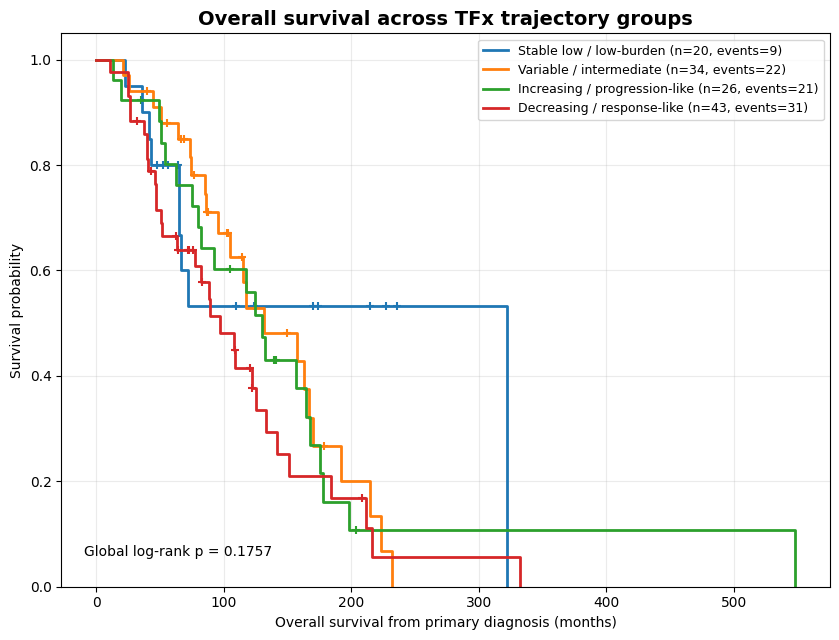


SURVIVAL ANALYSIS: OS across 4 TFx trajectory groups

Survival-ready patients:
123

Event distribution:
Dead/events: 83
Censored:    40

KM summary:
            Trajectory_4group  n_patients  n_events  n_censored  median_survival_months  global_logrank_chi2  global_logrank_p_value
      Stable low / low-burden          20         9          11              322.562628             4.947807                0.175659
      Variable / intermediate          34        22          12              131.515400             4.947807                0.175659
Increasing / progression-like          26        21           5              129.905544             4.947807                0.175659
   Decreasing / response-like          43        31          12               96.755647             4.947807                0.175659

Global log-rank test:
Chi-square = 4.9478
p-value    = 0.175659

Pairwise log-rank tests:
                      group_1                       group_2  logrank_chi_square  p_value  BH_q

In [9]:
# ============================================================
# Survival analysis across 4 TFx trajectory groups
# Kaplan-Meier + global log-rank + pairwise log-rank
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from statsmodels.stats.multitest import multipletests


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

survival_dir = BASE_DIR / "Survival"

survival_file = survival_dir / "AURORA_all_patients_median_TFx_OS_clean.csv"

trajectory_file = (
    BASE_DIR /
    "ichorCNA/Plot/Correlation_Clinical_variables/"
    "Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

out_dir = survival_dir / "KM_TFx_trajectory_4group"
out_dir.mkdir(parents=True, exist_ok=True)

print("Survival file:")
print(survival_file)

print("\nTrajectory file:")
print(trajectory_file)

print("\nOutput directory:")
print(out_dir)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_patient_id(x):
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def find_first_col(df, candidates, label):
    for c in candidates:
        if c in df.columns:
            return c

    raise ValueError(
        f"Could not find {label}. Tried: {candidates}\n"
        f"Available columns:\n{df.columns.tolist()}"
    )


def fmt_p(p):
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return "<0.001"
    return f"{p:.4f}"


# ============================================================
# 3. Read survival file
# ============================================================

surv_df = pd.read_csv(survival_file, dtype={"patient_id": str})

required_cols = ["patient_id", "median_TFx", "Overall_Survival_days", "Event"]
missing = [c for c in required_cols if c not in surv_df.columns]

if len(missing) > 0:
    raise ValueError(f"Missing required survival columns: {missing}")

surv_df["patient_id_clean"] = surv_df["patient_id"].apply(clean_patient_id)
surv_df["median_TFx"] = pd.to_numeric(surv_df["median_TFx"], errors="coerce")
surv_df["Overall_Survival_days"] = pd.to_numeric(
    surv_df["Overall_Survival_days"],
    errors="coerce"
)
surv_df["Event"] = pd.to_numeric(surv_df["Event"], errors="coerce")

print("\n========== Survival input ==========")
print("Rows:", surv_df.shape[0])
print("Patients:", surv_df["patient_id_clean"].nunique())
print("Patients with median_TFx:", surv_df["median_TFx"].notna().sum())
print("Patients with OS days:", surv_df["Overall_Survival_days"].notna().sum())
print("Patients with Event:", surv_df["Event"].notna().sum())


# ============================================================
# 4. Read trajectory file and collapse to one row per patient
# ============================================================

traj_df = pd.read_csv(trajectory_file, dtype=str)

print("\n========== Trajectory input ==========")
print("Rows:", traj_df.shape[0])
print("Columns:", traj_df.columns.tolist())

# Use exact column names from this trajectory file
traj_patient_col = "Patient_id"
traj_group_col = "Trajectory_4group"

print("\nUsing trajectory columns:")
print("Patient ID column:", traj_patient_col)
print("Trajectory group column:", traj_group_col)
traj_df["patient_id_clean"] = traj_df[traj_patient_col].apply(clean_patient_id)
traj_df["Trajectory_4group"] = traj_df[traj_group_col].astype(str).str.strip()

# Collapse to one trajectory group per patient
traj_patient = (
    traj_df
    .loc[
        traj_df["patient_id_clean"].notna()
        & traj_df["Trajectory_4group"].notna()
        & ~traj_df["Trajectory_4group"].isin(["", "nan", "NaN", "None"]),
        ["patient_id_clean", "Trajectory_4group"]
    ]
    .drop_duplicates()
)

# QC: patients with multiple trajectory labels
multi_traj = (
    traj_patient
    .groupby("patient_id_clean")["Trajectory_4group"]
    .nunique()
    .reset_index(name="n_trajectory_labels")
)

multi_traj = multi_traj[multi_traj["n_trajectory_labels"] > 1]

if multi_traj.shape[0] > 0:
    print("\nWARNING: Some patients have multiple trajectory labels.")
    print(multi_traj.to_string(index=False))
    raise ValueError("Please resolve multiple trajectory labels before survival analysis.")

traj_patient = traj_patient.drop_duplicates(subset=["patient_id_clean"])

print("\n========== Patient-level trajectory summary ==========")
print("Patients with trajectory group:", traj_patient.shape[0])
print(traj_patient["Trajectory_4group"].value_counts(dropna=False).to_string())


# ============================================================
# 5. Merge survival + trajectory
# ============================================================

merged = surv_df.merge(
    traj_patient,
    on="patient_id_clean",
    how="inner"
)

surv_traj = merged[
    merged["Overall_Survival_days"].notna()
    & merged["Event"].notna()
    & merged["Trajectory_4group"].notna()
].copy()

surv_traj["Event"] = surv_traj["Event"].astype(int)

# Convert survival time from days to months
DAYS_PER_MONTH = 365.25 / 12
surv_traj["Overall_Survival_months"] = (
    surv_traj["Overall_Survival_days"] / DAYS_PER_MONTH
)

surv_traj_file = out_dir / "AURORA_survival_ready_TFx_trajectory_4group.csv"
surv_traj.to_csv(surv_traj_file, index=False)

print("\n========== Survival-ready trajectory cohort ==========")
print("Patients:", surv_traj.shape[0])
print("Events/deaths:", int((surv_traj["Event"] == 1).sum()))
print("Censored:", int((surv_traj["Event"] == 0).sum()))
print("\nTrajectory group counts:")
print(surv_traj["Trajectory_4group"].value_counts(dropna=False).to_string())

if surv_traj.shape[0] == 0:
    raise RuntimeError("No patients with survival + trajectory group.")


# ============================================================
# 6. Kaplan-Meier and log-rank helper functions
# ============================================================

def km_curve(durations, events):
    data = pd.DataFrame({
        "time": pd.to_numeric(durations, errors="coerce"),
        "event": pd.to_numeric(events, errors="coerce")
    }).dropna()

    data = data.sort_values("time")

    event_times = sorted(data.loc[data["event"] == 1, "time"].unique())

    x = [0.0]
    y = [1.0]

    surv_prob = 1.0
    median_survival = np.nan
    rows = []

    for t in event_times:
        n_at_risk = int((data["time"] >= t).sum())
        n_events = int(((data["time"] == t) & (data["event"] == 1)).sum())
        n_censored = int(((data["time"] == t) & (data["event"] == 0)).sum())

        if n_at_risk > 0:
            surv_prob = surv_prob * (1 - n_events / n_at_risk)

        x.append(float(t))
        y.append(float(surv_prob))

        rows.append({
            "time": t,
            "n_at_risk": n_at_risk,
            "n_events": n_events,
            "n_censored": n_censored,
            "survival": surv_prob
        })

        if pd.isna(median_survival) and surv_prob <= 0.5:
            median_survival = t

    max_time = data["time"].max()

    if len(x) == 1 or x[-1] < max_time:
        x.append(float(max_time))
        y.append(float(surv_prob))

    return np.array(x), np.array(y), pd.DataFrame(rows), median_survival


def survival_at_censor_times(event_table, censor_times):
    surv_vals = []

    for t in censor_times:
        sub = event_table[event_table["time"] <= t]

        if sub.empty:
            surv_vals.append(1.0)
        else:
            surv_vals.append(float(sub.iloc[-1]["survival"]))

    return np.array(surv_vals)


def logrank_global(df, time_col, event_col, group_col):
    """
    Global log-rank test for >2 groups.
    """
    d = df[[time_col, event_col, group_col]].dropna().copy()
    groups = sorted(d[group_col].unique())

    k = len(groups)

    observed = np.zeros(k)
    expected = np.zeros(k)
    var = np.zeros((k, k))

    event_times = sorted(d.loc[d[event_col] == 1, time_col].unique())

    for t in event_times:
        at_risk = np.array([
            ((d[group_col] == g) & (d[time_col] >= t)).sum()
            for g in groups
        ], dtype=float)

        events = np.array([
            ((d[group_col] == g) & (d[time_col] == t) & (d[event_col] == 1)).sum()
            for g in groups
        ], dtype=float)

        n = at_risk.sum()
        m = events.sum()

        if n <= 1 or m == 0:
            continue

        observed += events
        expected += m * at_risk / n

        factor = m * (n - m) / (n * n * (n - 1))

        for i in range(k):
            for j in range(k):
                if i == j:
                    var[i, j] += factor * at_risk[i] * (n - at_risk[i])
                else:
                    var[i, j] -= factor * at_risk[i] * at_risk[j]

    oe = observed - expected

    # Drop last group to avoid singular covariance
    oe_reduced = oe[:-1]
    var_reduced = var[:-1, :-1]

    try:
        chi_sq = float(oe_reduced.T @ np.linalg.pinv(var_reduced) @ oe_reduced)
        p_value = chi2.sf(chi_sq, df=k - 1)
    except Exception:
        chi_sq = np.nan
        p_value = np.nan

    return chi_sq, p_value, groups, observed, expected


def logrank_two_group(df, time_col, event_col, group_col, group_a, group_b):
    d = df[df[group_col].isin([group_a, group_b])].copy()

    event_times = sorted(d.loc[d[event_col] == 1, time_col].dropna().unique())

    O_a = 0.0
    E_a = 0.0
    V_a = 0.0

    for t in event_times:
        n_a = ((d[group_col] == group_a) & (d[time_col] >= t)).sum()
        n_b = ((d[group_col] == group_b) & (d[time_col] >= t)).sum()
        n_total = n_a + n_b

        d_a = ((d[group_col] == group_a) & (d[time_col] == t) & (d[event_col] == 1)).sum()
        d_b = ((d[group_col] == group_b) & (d[time_col] == t) & (d[event_col] == 1)).sum()
        d_total = d_a + d_b

        if n_total <= 1 or d_total == 0:
            continue

        e_a = d_total * (n_a / n_total)

        v_a = (
            n_a * n_b * d_total * (n_total - d_total)
        ) / (
            (n_total ** 2) * (n_total - 1)
        )

        O_a += d_a
        E_a += e_a
        V_a += v_a

    if V_a > 0:
        chi_sq = ((O_a - E_a) ** 2) / V_a
        p_value = chi2.sf(chi_sq, df=1)
    else:
        chi_sq = np.nan
        p_value = np.nan

    return chi_sq, p_value


# ============================================================
# 7. Global log-rank test
# ============================================================

time_col = "Overall_Survival_months"
event_col = "Event"
group_col = "Trajectory_4group"

global_chi2, global_p, groups, observed, expected = logrank_global(
    surv_traj,
    time_col=time_col,
    event_col=event_col,
    group_col=group_col
)

print("\n========== Global log-rank test across trajectory groups ==========")
print("Groups:", groups)
print(f"Chi-square = {global_chi2:.4f}")
print(f"p-value    = {global_p:.6g}")


# ============================================================
# 8. KM plot for 4 trajectory groups
# ============================================================

# Use group order by median survival, longest to shortest, for readable legend
group_order_table = []

for group in groups:
    sub = surv_traj[surv_traj[group_col] == group].copy()
    _, _, _, median_surv = km_curve(sub[time_col], sub[event_col])

    group_order_table.append({
    "Trajectory_4group": group,
    "median_survival_months": median_surv,
    "n_patients": sub.shape[0]
    })

group_order_df = pd.DataFrame(group_order_table)

group_order = (
    group_order_df
    .sort_values(
        by=["median_survival_months", "n_patients"],
        ascending=[False, False],
        na_position="last"
    )["Trajectory_4group"]
    .tolist()
)

print("\nGroup plotting order:")
print(group_order)

km_summary_rows = []

fig, ax = plt.subplots(figsize=(8.5, 6.5))

for group in group_order:
    sub = surv_traj[surv_traj[group_col] == group].copy()

    x, y, event_table, median_surv = km_curve(
        sub[time_col],
        sub[event_col]
    )

    n_patients = sub.shape[0]
    n_events = int((sub[event_col] == 1).sum())
    n_censored = int((sub[event_col] == 0).sum())

    ax.step(
        x,
        y,
        where="post",
        linewidth=2,
        label=f"{group} (n={n_patients}, events={n_events})"
    )

    censor_times = sub.loc[sub[event_col] == 0, time_col].dropna().values
    censor_y = survival_at_censor_times(event_table, censor_times)

    if len(censor_times) > 0:
        ax.scatter(
            censor_times,
            censor_y,
            marker="+",
            s=35
        )

    km_summary_rows.append({
    "Trajectory_4group": group,
    "n_patients": n_patients,
    "n_events": n_events,
    "n_censored": n_censored,
    "median_survival_months": median_surv,
    "global_logrank_chi2": global_chi2,
    "global_logrank_p_value": global_p
    })

ax.set_title(
    "Overall survival across TFx trajectory groups",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Overall survival from primary diagnosis (months)")
ax.set_ylabel("Survival probability")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)

ax.text(
    0.03,
    0.05,
    f"Global log-rank p = {fmt_p(global_p)}",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10
)

ax.legend(loc="best", fontsize=9)

plt.tight_layout()

km_png = out_dir / "KM_OS_by_TFx_trajectory_4group.png"
km_pdf = out_dir / "KM_OS_by_TFx_trajectory_4group.pdf"

plt.savefig(km_png, dpi=300)
plt.savefig(km_pdf)

plt.show()

plt.close()

km_summary = pd.DataFrame(km_summary_rows)

km_summary_file = out_dir / "KM_summary_OS_by_TFx_trajectory_4group.csv"
km_summary.to_csv(km_summary_file, index=False)


# ============================================================
# 9. Pairwise log-rank tests with BH correction
# ============================================================

pairwise_rows = []

for i in range(len(groups)):
    for j in range(i + 1, len(groups)):
        g1 = groups[i]
        g2 = groups[j]

        chi_sq, p_value = logrank_two_group(
            surv_traj,
            time_col=time_col,
            event_col=event_col,
            group_col=group_col,
            group_a=g1,
            group_b=g2
        )

        pairwise_rows.append({
            "group_1": g1,
            "group_2": g2,
            "logrank_chi_square": chi_sq,
            "p_value": p_value
        })

pairwise = pd.DataFrame(pairwise_rows)

if pairwise.shape[0] > 0:
    pairwise["BH_q_value"] = multipletests(
        pairwise["p_value"].fillna(1),
        method="fdr_bh"
    )[1]

    pairwise["significant_BH_0.05"] = pairwise["BH_q_value"] < 0.05

pairwise_file = out_dir / "Pairwise_logrank_TFx_trajectory_4group.csv"
pairwise.to_csv(pairwise_file, index=False)


# ============================================================
# 10. Print final results on screen
# ============================================================

print("\n" + "=" * 80)
print("SURVIVAL ANALYSIS: OS across 4 TFx trajectory groups")
print("=" * 80)

print("\nSurvival-ready patients:")
print(surv_traj.shape[0])

print("\nEvent distribution:")
print(f"Dead/events: {int((surv_traj['Event'] == 1).sum())}")
print(f"Censored:    {int((surv_traj['Event'] == 0).sum())}")

print("\nKM summary:")
print(km_summary.to_string(index=False))

print("\nGlobal log-rank test:")
print(f"Chi-square = {global_chi2:.4f}")
print(f"p-value    = {global_p:.6g}")

print("\nPairwise log-rank tests:")
print(pairwise.to_string(index=False))

print("\nSaved files:")
print(km_png)
print(km_pdf)
print(km_summary_file)
print(pairwise_file)
print(surv_traj_file)

print("=" * 80)

In [11]:
print("\n========== Survival grouping used ==========")
print("Grouping variable: Trajectory_4group")
print("No median TFx cutpoint is used for this 4-group KM plot.")

print("\nTrajectory group counts:")
print(
    surv_traj["Trajectory_4group"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nMedian TFx and OS within each trajectory group, descriptive only:")
print(
    surv_traj
    .groupby("Trajectory_4group")
    .agg(
        n_patients=("patient_id_clean", "nunique"),
        median_TFx_within_group=("median_TFx", "median"),
        median_OS_months=("Overall_Survival_months", "median"),
        n_events=("Event", "sum")
    )
    .reset_index()
    .to_string(index=False)
)


========== Survival grouping used ==========
Grouping variable: Trajectory_4group
No median TFx cutpoint is used for this 4-group KM plot.

Trajectory group counts:
Decreasing / response-like       43
Variable / intermediate          34
Increasing / progression-like    26
Stable low / low-burden          20

Median TFx and OS within each trajectory group, descriptive only:
            Trajectory_4group  n_patients  median_TFx_within_group  median_OS_months  n_events
   Decreasing / response-like          43                  7.95200         75.630390        31
Increasing / progression-like          26                  9.34875        121.051335        21
      Stable low / low-burden          20                  5.93300         66.004107         9
      Variable / intermediate          34                  6.21325         99.104723        22


Survival file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/AURORA_all_patients_median_TFx_OS_clean.csv

Trajectory file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/KM_TFx_trajectory_group_specific_median_split

========== Survival input ==========
Rows: 273
Patients: 273
Patients with median_TFx: 262
Patients with OS days: 271
Patients with Event: 271

========== Trajectory input ==========
Rows: 583
Columns: ['Collaborator_sample_id', 'Patient_id', 'Patient_Identifier', 'Blood_Draw_Order', 'Trajectory_4group', 'n_draws', 'Histological_subtype', 'ER_Status', 'PR_Status', 'HER2_Status', 'Molecular_subtype', 'Mean_coverage', 'Tumor_Fraction', 'Tumor_Fraction_percent', 'Ploidy', 'Subclone Fraction', 'Frac. Genome Subclonal', 'Frac. CNA Subclonal', 'Frac_Subnucleosom

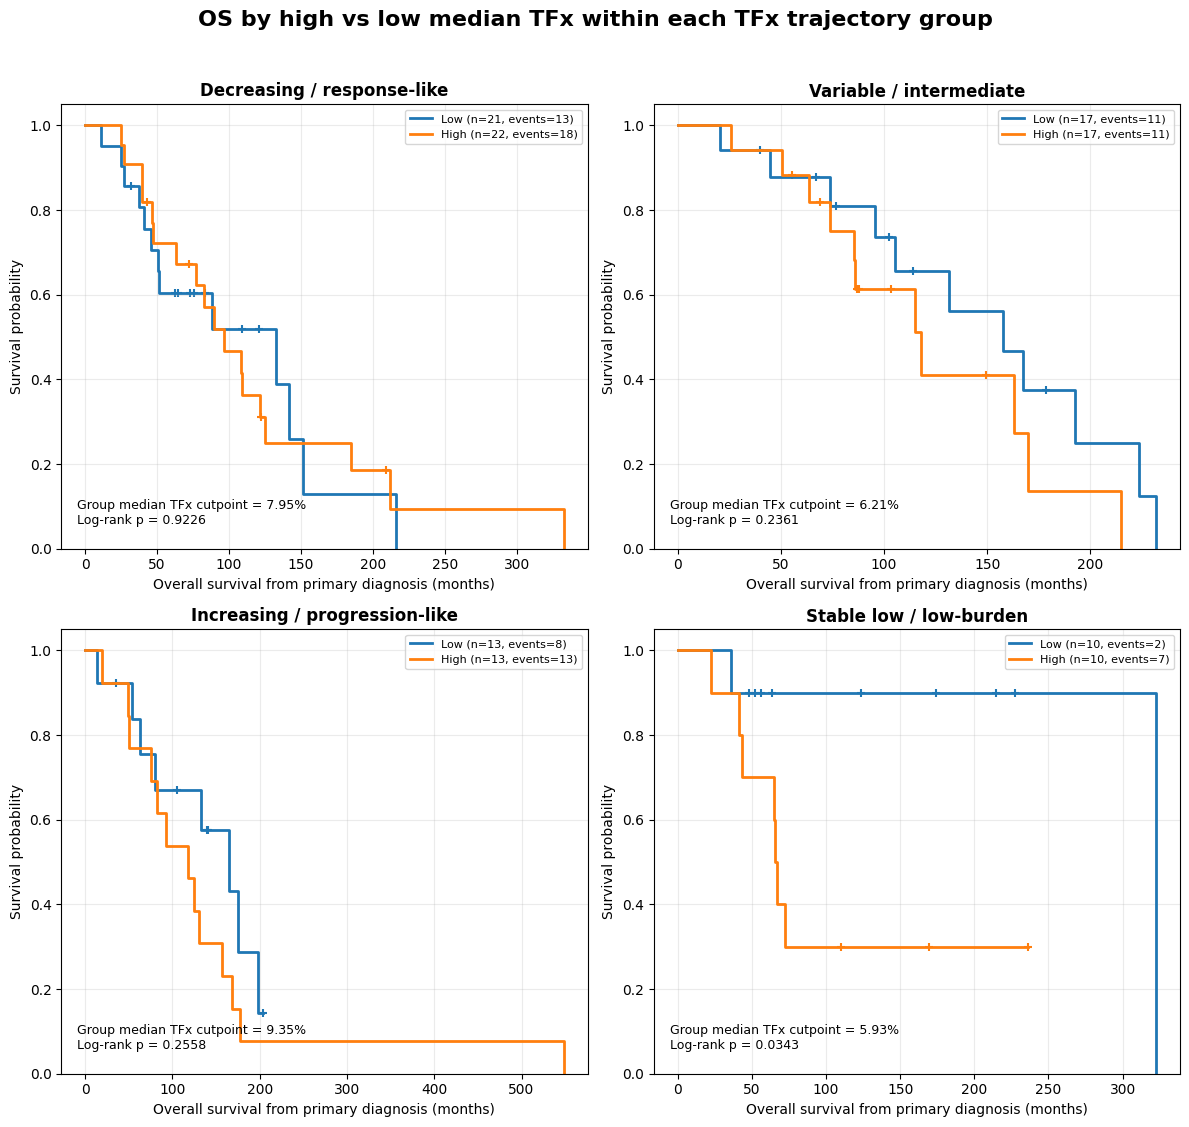


SURVIVAL ANALYSIS: high vs low median TFx within each trajectory group

Main split summary:
            Trajectory_4group median_TFx_within_trajectory_group  n_patients  n_events  n_censored  median_TFx  median_OS_months  cutpoint_used  event_rate_percent
   Decreasing / response-like  High median TFx within trajectory          22        18           4    10.63275         86.012320        7.95200                81.8
   Decreasing / response-like   Low median TFx within trajectory          21        13           8     5.51150         64.295688        7.95200                61.9
Increasing / progression-like  High median TFx within trajectory          13        13           0    26.30000        117.355236        9.34875               100.0
Increasing / progression-like   Low median TFx within trajectory          13         8           5     5.57100        132.665298        9.34875                61.5
      Stable low / low-burden  High median TFx within trajectory          10         7 

In [12]:
# ============================================================
# Survival analysis:
# Within each TFx trajectory group, split patients by group-specific median TFx
# KM + log-rank for low vs high median TFx inside each trajectory group
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from statsmodels.stats.multitest import multipletests


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

survival_dir = BASE_DIR / "Survival"

survival_file = survival_dir / "AURORA_all_patients_median_TFx_OS_clean.csv"

trajectory_file = (
    BASE_DIR /
    "ichorCNA/Plot/Correlation_Clinical_variables/"
    "Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

out_dir = survival_dir / "KM_TFx_trajectory_group_specific_median_split"
out_dir.mkdir(parents=True, exist_ok=True)

print("Survival file:")
print(survival_file)

print("\nTrajectory file:")
print(trajectory_file)

print("\nOutput directory:")
print(out_dir)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_patient_id(x):
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def fmt_p(p):
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return "<0.001"
    return f"{p:.4f}"


def km_curve(durations, events):
    data = pd.DataFrame({
        "time": pd.to_numeric(durations, errors="coerce"),
        "event": pd.to_numeric(events, errors="coerce")
    }).dropna()

    data = data.sort_values("time")

    event_times = sorted(data.loc[data["event"] == 1, "time"].unique())

    x = [0.0]
    y = [1.0]

    surv_prob = 1.0
    median_survival = np.nan
    rows = []

    for t in event_times:
        n_at_risk = int((data["time"] >= t).sum())
        n_events = int(((data["time"] == t) & (data["event"] == 1)).sum())
        n_censored = int(((data["time"] == t) & (data["event"] == 0)).sum())

        if n_at_risk > 0:
            surv_prob = surv_prob * (1 - n_events / n_at_risk)

        x.append(float(t))
        y.append(float(surv_prob))

        rows.append({
            "time": t,
            "n_at_risk": n_at_risk,
            "n_events": n_events,
            "n_censored": n_censored,
            "survival": surv_prob
        })

        if pd.isna(median_survival) and surv_prob <= 0.5:
            median_survival = t

    max_time = data["time"].max()

    if len(x) == 1 or x[-1] < max_time:
        x.append(float(max_time))
        y.append(float(surv_prob))

    return np.array(x), np.array(y), pd.DataFrame(rows), median_survival


def survival_at_censor_times(event_table, censor_times):
    surv_vals = []

    for t in censor_times:
        sub = event_table[event_table["time"] <= t]

        if sub.empty:
            surv_vals.append(1.0)
        else:
            surv_vals.append(float(sub.iloc[-1]["survival"]))

    return np.array(surv_vals)


def logrank_two_group(df, time_col, event_col, group_col, group_a, group_b):
    d = df[df[group_col].isin([group_a, group_b])].copy()

    event_times = sorted(d.loc[d[event_col] == 1, time_col].dropna().unique())

    O_a = 0.0
    E_a = 0.0
    V_a = 0.0

    for t in event_times:
        n_a = ((d[group_col] == group_a) & (d[time_col] >= t)).sum()
        n_b = ((d[group_col] == group_b) & (d[time_col] >= t)).sum()
        n_total = n_a + n_b

        d_a = ((d[group_col] == group_a) & (d[time_col] == t) & (d[event_col] == 1)).sum()
        d_b = ((d[group_col] == group_b) & (d[time_col] == t) & (d[event_col] == 1)).sum()
        d_total = d_a + d_b

        if n_total <= 1 or d_total == 0:
            continue

        e_a = d_total * (n_a / n_total)

        v_a = (
            n_a * n_b * d_total * (n_total - d_total)
        ) / (
            (n_total ** 2) * (n_total - 1)
        )

        O_a += d_a
        E_a += e_a
        V_a += v_a

    if V_a > 0:
        chi_sq = ((O_a - E_a) ** 2) / V_a
        p_value = chi2.sf(chi_sq, df=1)
    else:
        chi_sq = np.nan
        p_value = np.nan

    return chi_sq, p_value


# ============================================================
# 3. Read survival file
# ============================================================

surv_df = pd.read_csv(survival_file, dtype={"patient_id": str})

required_cols = ["patient_id", "median_TFx", "Overall_Survival_days", "Event"]
missing_cols = [c for c in required_cols if c not in surv_df.columns]

if len(missing_cols) > 0:
    raise ValueError(f"Missing required survival columns: {missing_cols}")

surv_df["patient_id_clean"] = surv_df["patient_id"].apply(clean_patient_id)
surv_df["median_TFx"] = pd.to_numeric(surv_df["median_TFx"], errors="coerce")
surv_df["Overall_Survival_days"] = pd.to_numeric(
    surv_df["Overall_Survival_days"],
    errors="coerce"
)
surv_df["Event"] = pd.to_numeric(surv_df["Event"], errors="coerce")

print("\n========== Survival input ==========")
print("Rows:", surv_df.shape[0])
print("Patients:", surv_df["patient_id_clean"].nunique())
print("Patients with median_TFx:", surv_df["median_TFx"].notna().sum())
print("Patients with OS days:", surv_df["Overall_Survival_days"].notna().sum())
print("Patients with Event:", surv_df["Event"].notna().sum())


# ============================================================
# 4. Read trajectory file
# ============================================================

traj_df = pd.read_csv(trajectory_file, dtype=str)

print("\n========== Trajectory input ==========")
print("Rows:", traj_df.shape[0])
print("Columns:", traj_df.columns.tolist())

# Exact column names in your trajectory file
traj_patient_col = "Patient_id"
traj_group_col = "Trajectory_4group"

if traj_patient_col not in traj_df.columns:
    raise ValueError(f"Missing column in trajectory file: {traj_patient_col}")

if traj_group_col not in traj_df.columns:
    raise ValueError(f"Missing column in trajectory file: {traj_group_col}")

traj_df["patient_id_clean"] = traj_df[traj_patient_col].apply(clean_patient_id)
traj_df["Trajectory_4group"] = traj_df[traj_group_col].astype(str).str.strip()

traj_patient = (
    traj_df[
        traj_df["patient_id_clean"].notna()
        & traj_df["Trajectory_4group"].notna()
        & ~traj_df["Trajectory_4group"].isin(["", "nan", "NaN", "None"])
    ][["patient_id_clean", "Trajectory_4group"]]
    .drop_duplicates()
)

# QC: one trajectory label per patient
multi_traj = (
    traj_patient
    .groupby("patient_id_clean")["Trajectory_4group"]
    .nunique()
    .reset_index(name="n_trajectory_labels")
)

multi_traj = multi_traj[multi_traj["n_trajectory_labels"] > 1]

if multi_traj.shape[0] > 0:
    print("\nWARNING: patients with multiple trajectory labels:")
    print(multi_traj.to_string(index=False))
    raise ValueError("Please resolve multiple trajectory labels first.")

traj_patient = traj_patient.drop_duplicates(subset=["patient_id_clean"])

print("\n========== Patient-level trajectory summary ==========")
print("Patients with trajectory:", traj_patient.shape[0])
print(traj_patient["Trajectory_4group"].value_counts(dropna=False).to_string())


# ============================================================
# 5. Merge survival + trajectory
# ============================================================

surv_traj = surv_df.merge(
    traj_patient,
    on="patient_id_clean",
    how="inner"
)

surv_traj = surv_traj[
    surv_traj["median_TFx"].notna()
    & surv_traj["Overall_Survival_days"].notna()
    & surv_traj["Event"].notna()
    & surv_traj["Trajectory_4group"].notna()
].copy()

surv_traj["Event"] = surv_traj["Event"].astype(int)
# Convert survival time from days to months
DAYS_PER_MONTH = 365.25 / 12
surv_traj["Overall_Survival_months"] = (
    surv_traj["Overall_Survival_days"] / DAYS_PER_MONTH
)

print("\n========== Survival-ready trajectory cohort ==========")
print("Patients:", surv_traj.shape[0])
print("Events:", int((surv_traj["Event"] == 1).sum()))
print("Censored:", int((surv_traj["Event"] == 0).sum()))
print("\nTrajectory counts:")
print(surv_traj["Trajectory_4group"].value_counts(dropna=False).to_string())

if surv_traj.shape[0] == 0:
    raise RuntimeError("No survival-ready patients after merging trajectory.")


# ============================================================
# 6. Create group-specific median TFx split
# ============================================================

surv_traj["trajectory_specific_median_TFx_cutpoint"] = (
    surv_traj
    .groupby("Trajectory_4group")["median_TFx"]
    .transform("median")
)

surv_traj["median_TFx_within_trajectory_group"] = np.where(
    surv_traj["median_TFx"] >= surv_traj["trajectory_specific_median_TFx_cutpoint"],
    "High median TFx within trajectory",
    "Low median TFx within trajectory"
)

split_summary = (
    surv_traj
    .groupby(["Trajectory_4group", "median_TFx_within_trajectory_group"])
    .agg(
        n_patients=("patient_id", "count"),
        n_events=("Event", "sum"),
        n_censored=("Event", lambda x: int((x == 0).sum())),
        median_TFx=("median_TFx", "median"),
        median_OS_months=("Overall_Survival_months", "median"),
        cutpoint_used=("trajectory_specific_median_TFx_cutpoint", "first")
    )
    .reset_index()
)

split_summary["event_rate_percent"] = (
    split_summary["n_events"] / split_summary["n_patients"] * 100
).round(1)

split_summary_file = out_dir / "Trajectory_group_specific_median_TFx_split_summary.csv"
split_summary.to_csv(split_summary_file, index=False)

surv_traj_file = out_dir / "AURORA_survival_ready_TFx_trajectory_group_specific_median_split.csv"
surv_traj.to_csv(surv_traj_file, index=False)

print("\n========== Group-specific median TFx split summary ==========")
print(split_summary.to_string(index=False))


# ============================================================
# 7. Log-rank test within each trajectory group
# ============================================================

time_col = "Overall_Survival_months"
event_col = "Event"
split_col = "median_TFx_within_trajectory_group"

within_rows = []

for traj_group, sub in surv_traj.groupby("Trajectory_4group"):
    n_total = sub.shape[0]

    groups_present = sorted(sub[split_col].dropna().unique().tolist())

    if len(groups_present) < 2:
        chi_sq = np.nan
        p_value = np.nan
    else:
        chi_sq, p_value = logrank_two_group(
            sub,
            time_col=time_col,
            event_col=event_col,
            group_col=split_col,
            group_a="Low median TFx within trajectory",
            group_b="High median TFx within trajectory"
        )

    within_rows.append({
        "Trajectory_4group": traj_group,
        "n_patients": n_total,
        "cutpoint_group_specific_median_TFx": sub["trajectory_specific_median_TFx_cutpoint"].iloc[0],
        "logrank_chi_square": chi_sq,
        "p_value": p_value
    })

within_tests = pd.DataFrame(within_rows)

within_tests["BH_q_value"] = multipletests(
    within_tests["p_value"].fillna(1),
    method="fdr_bh"
)[1]

within_tests["significant_BH_0.05"] = within_tests["BH_q_value"] < 0.05

within_tests_file = out_dir / "Within_trajectory_logrank_high_vs_low_median_TFx.csv"
within_tests.to_csv(within_tests_file, index=False)

print("\n========== Within-trajectory log-rank tests ==========")
print(within_tests.to_string(index=False))


# ============================================================
# 8. Plot KM curves separately for each trajectory group
# ============================================================

trajectory_groups = (
    surv_traj["Trajectory_4group"]
    .value_counts()
    .index
    .tolist()
)

n_groups = len(trajectory_groups)

ncols = 2
nrows = int(np.ceil(n_groups / ncols))

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(12, 5.5 * nrows),
    squeeze=False
)

axes_flat = axes.flatten()

plot_summary_rows = []

for idx, traj_group in enumerate(trajectory_groups):
    ax = axes_flat[idx]

    sub_traj = surv_traj[surv_traj["Trajectory_4group"] == traj_group].copy()

    test_row = within_tests[
        within_tests["Trajectory_4group"].eq(traj_group)
    ].iloc[0]

    p_value = test_row["p_value"]
    cutpoint = test_row["cutpoint_group_specific_median_TFx"]

    for split_group in [
        "Low median TFx within trajectory",
        "High median TFx within trajectory"
    ]:
        sub = sub_traj[sub_traj[split_col] == split_group].copy()

        if sub.shape[0] == 0:
            continue

        x, y, event_table, median_surv = km_curve(
            sub[time_col],
            sub[event_col]
        )

        n_patients = sub.shape[0]
        n_events = int((sub[event_col] == 1).sum())
        n_censored = int((sub[event_col] == 0).sum())

        label = split_group.replace(" median TFx within trajectory", "")
        label = f"{label} (n={n_patients}, events={n_events})"

        ax.step(
            x,
            y,
            where="post",
            linewidth=2,
            label=label
        )

        censor_times = sub.loc[sub[event_col] == 0, time_col].dropna().values
        censor_y = survival_at_censor_times(event_table, censor_times)

        if len(censor_times) > 0:
            ax.scatter(
                censor_times,
                censor_y,
                marker="+",
                s=35
            )

        plot_summary_rows.append({
            "Trajectory_4group": traj_group,
            "median_TFx_group": split_group,
            "n_patients": n_patients,
            "n_events": n_events,
            "n_censored": n_censored,
            "median_survival_months": median_surv,
            "cutpoint_group_specific_median_TFx": cutpoint,
            "within_trajectory_logrank_p_value": p_value
        })

    ax.set_title(
        f"{traj_group}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Overall survival from primary diagnosis (months)")
    ax.set_ylabel("Survival probability")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)

    ax.text(
        0.03,
        0.05,
        f"Group median TFx cutpoint = {cutpoint:.2f}%\nLog-rank p = {fmt_p(p_value)}",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=9
    )

    ax.legend(loc="best", fontsize=8)

# Remove unused panels
for j in range(idx + 1, len(axes_flat)):
    fig.delaxes(axes_flat[j])

fig.suptitle(
    "OS by high vs low median TFx within each TFx trajectory group",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

km_png = out_dir / "KM_OS_high_vs_low_median_TFx_within_each_trajectory_group.png"
km_pdf = out_dir / "KM_OS_high_vs_low_median_TFx_within_each_trajectory_group.pdf"

plt.savefig(km_png, dpi=300, bbox_inches="tight")
plt.savefig(km_pdf, bbox_inches="tight")

plt.show()

plt.close()

plot_summary = pd.DataFrame(plot_summary_rows)

plot_summary_file = out_dir / "KM_summary_high_vs_low_median_TFx_within_each_trajectory_group.csv"
plot_summary.to_csv(plot_summary_file, index=False)


# ============================================================
# 9. Optional combined 8-group KM plot
# ============================================================
# This is busier, but useful as a QC/global visual.
# ============================================================

surv_traj["Trajectory_plus_TFx_group"] = (
    surv_traj["Trajectory_4group"]
    + " | "
    + surv_traj["median_TFx_within_trajectory_group"].str.replace(
        " median TFx within trajectory",
        "",
        regex=False
    )
)

fig, ax = plt.subplots(figsize=(10, 7))

combined_groups = (
    surv_traj["Trajectory_plus_TFx_group"]
    .value_counts()
    .index
    .tolist()
)

for group in combined_groups:
    sub = surv_traj[surv_traj["Trajectory_plus_TFx_group"] == group].copy()

    x, y, event_table, median_surv = km_curve(
        sub[time_col],
        sub[event_col]
    )

    n_patients = sub.shape[0]
    n_events = int((sub[event_col] == 1).sum())

    ax.step(
        x,
        y,
        where="post",
        linewidth=1.8,
        label=f"{group} (n={n_patients}, events={n_events})"
    )

ax.set_title(
    "OS across trajectory groups stratified by within-group median TFx",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Overall survival from primary diagnosis (months)")
ax.set_ylabel("Survival probability")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend(loc="best", fontsize=7)

plt.tight_layout()

combined_png = out_dir / "KM_OS_8groups_trajectory_plus_within_group_median_TFx.png"
combined_pdf = out_dir / "KM_OS_8groups_trajectory_plus_within_group_median_TFx.pdf"

plt.savefig(combined_png, dpi=300, bbox_inches="tight")
plt.savefig(combined_pdf, bbox_inches="tight")

plt.close()


# ============================================================
# 10. Print final output
# ============================================================

print("\n" + "=" * 90)
print("SURVIVAL ANALYSIS: high vs low median TFx within each trajectory group")
print("=" * 90)

print("\nMain split summary:")
print(split_summary.to_string(index=False))

print("\nWithin-trajectory log-rank tests:")
print(within_tests.to_string(index=False))

print("\nKM plot summary:")
print(plot_summary.to_string(index=False))

print("\nSaved files:")
print(surv_traj_file)
print(split_summary_file)
print(within_tests_file)
print(plot_summary_file)
print(km_png)
print(km_pdf)
print(combined_png)
print(combined_pdf)

print("=" * 90)